In [235]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Beginning by importing Pandas, Matplotlib and NumPy libraries.

In [236]:
cpi_data = pd.read_csv("BankofCanadaFile.csv", skiprows=8)
    # Reading the CSV file using Pandas.
    # Skipping the first 8 rows to avoid unnecessary/unformated data.
display(cpi_data)

,date,STATIC_INFLATIONCALC
0,1914-01-01,6.0
1,1914-02-01,6.0
2,1914-03-01,6.0
3,1914-04-01,6.0
4,1914-05-01,5.9
...,...,...
1350,2026-05-01,169.6
1351,2026-06-01,169.0
1352,2026-07-01,169.9
1353,2026-08-01,169.8


In [237]:
print(cpi_data.info())
print(20*'-')
print(cpi_data.dtypes)
print(20*'-')
print(cpi_data.shape)
print(20*'-')
print(cpi_data['date'])

# Understanding data

<class 'pandas.DataFrame'>
RangeIndex: 1355 entries, 0 to 1354
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   date                  1355 non-null   str    
 1   STATIC_INFLATIONCALC  1355 non-null   float64
dtypes: float64(1), str(1)
memory usage: 21.3 KB
None
--------------------
date                        str
STATIC_INFLATIONCALC    float64
dtype: object
--------------------
(1355, 2)
--------------------
0       1914-01-01
1       1914-02-01
2       1914-03-01
3       1914-04-01
4       1914-05-01
           ...    
1350    2026-05-01
1351    2026-06-01
1352    2026-07-01
1353    2026-08-01
1354    2026-09-01
Name: date, Length: 1355, dtype: str


In [238]:
years=np.linspace(1914,2026,1355)
print(years)

# I equally divided up each year that the data is available for, intending to use this as my x-axis for the figure.

[1914.         1914.08271787 1914.16543575 ... 2025.83456425 2025.91728213
 2026.        ]


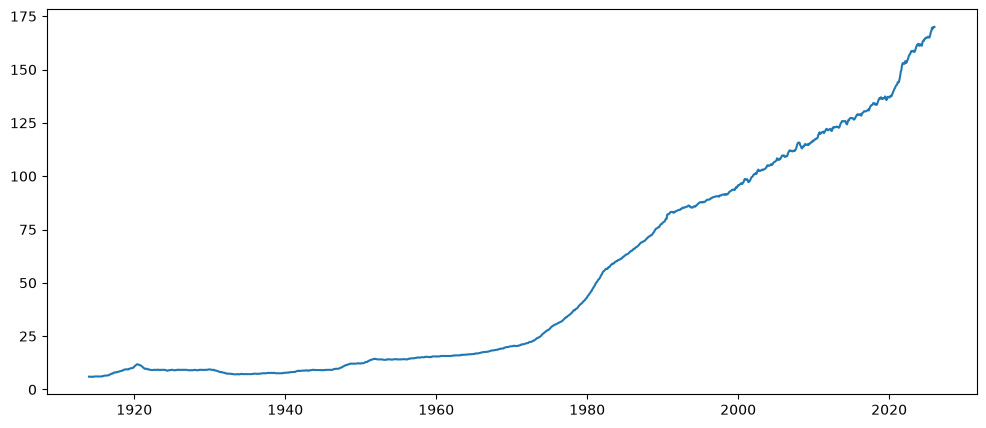

In [239]:
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(years, cpi_data['STATIC_INFLATIONCALC'])
    # This method works, but I researched documentation to find possibly better methods to use dates as an x-axis.
plt.show()

<class 'pandas.Series'>
datetime64[us]
--------------------


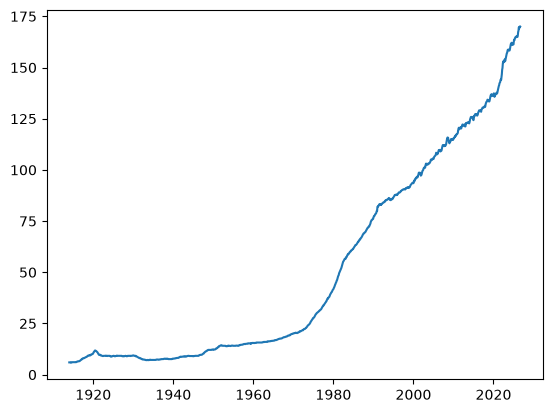

In [240]:
cpi_data['date'] = pd.to_datetime(cpi_data['date'])
    # This is the best alternative found. 
    # Using to_datetime allows Pandas and Matplotlib to recognize the data in the CSV file's 'date' column as dates.

print(type(cpi_data['date']))
print(cpi_data['date'].dtypes)
    # Note, the 'date' data is now of a different type: datetime64.
print(20*'-')

plt.plot(cpi_data['date'],cpi_data['STATIC_INFLATIONCALC'])
    # This plot gives me the time series for the CPI level. Next, I need the plot for annual percentage change.
plt.show()

In [241]:
# Renaming the CPI value column for ease and understanding.
cpi_data = cpi_data.rename(columns={'STATIC_INFLATIONCALC':'cpi'})
display(cpi_data)

,date,cpi
0,1914-01-01,6.0
1,1914-02-01,6.0
2,1914-03-01,6.0
3,1914-04-01,6.0
4,1914-05-01,5.9
...,...,...
1350,2026-05-01,169.6
1351,2026-06-01,169.0
1352,2026-07-01,169.9
1353,2026-08-01,169.8


In [242]:
# When researching percent changes, I discovered that Pandas has a function that calculates the change with specified intervals.

cpi_data['annual_change'] = cpi_data['cpi'].pct_change(periods=12)*100
    # Here, I created a separate column for the percent changes in CPI from year to year.
    # This is what I will use as the y-values for the CPI's annual percent change.

print(cpi_data[0:16])
print(cpi_data[-6:-1])
print(cpi_data[1200:1215])
    # Logic/sanity checks.

         date  cpi  annual_change
0  1914-01-01  6.0            NaN
1  1914-02-01  6.0            NaN
2  1914-03-01  6.0            NaN
3  1914-04-01  6.0            NaN
4  1914-05-01  5.9            NaN
5  1914-06-01  6.0            NaN
6  1914-07-01  5.9            NaN
7  1914-08-01  6.0            NaN
8  1914-09-01  6.0            NaN
9  1914-10-01  6.1            NaN
10 1914-11-01  6.1            NaN
11 1914-12-01  6.1            NaN
12 1915-01-01  6.1       1.666667
13 1915-02-01  6.1       1.666667
14 1915-03-01  6.1       1.666667
15 1915-04-01  6.1       1.666667
           date    cpi  annual_change
1349 2026-04-01  168.0       2.815177
1350 2026-05-01  169.6       3.225806
1351 2026-06-01  169.0       2.798054
1352 2026-07-01  169.9       3.032141
1353 2026-08-01  169.8       3.033981
           date    cpi  annual_change
1200 2013-11-01  123.0       0.902379
1201 2013-12-01  122.7       1.237624
1202 2014-01-01  123.1       1.483924
1203 2014-02-01  124.1       1.140994
1204

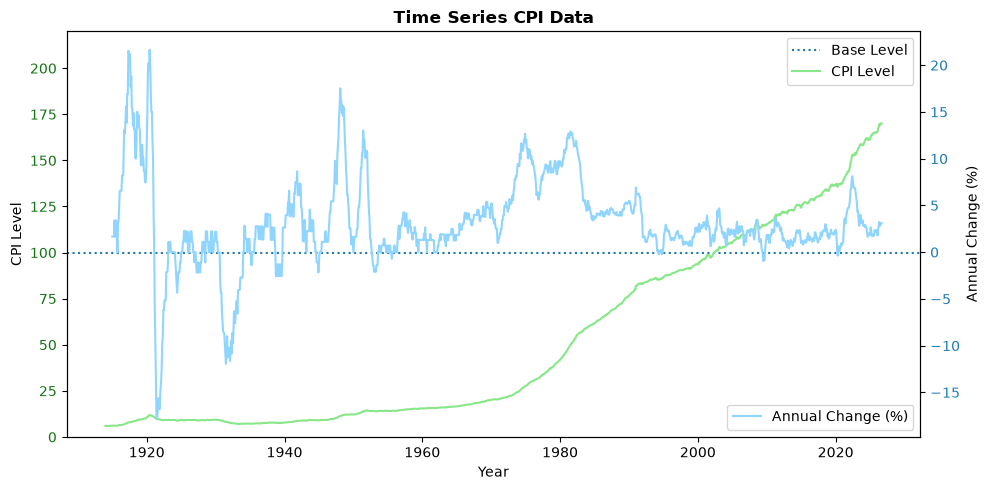

In [217]:
# Using plot documentation, my new annual_change column, and my datetime plot from earlier, I can finally plot the figure:

years = cpi_data['date']
cpi_level = cpi_data['cpi']
annual_cpi_change = cpi_data['annual_change']

# Defining y-values and common x-values. Also defining base value.

fig, ax1 = plt.subplots(figsize=(10,5), layout='tight', sharex=True)
    # Create the main figure on which everything is to be plotted.

ax1.axhline(y=100, ls=':', label='Base Level')
    # Base line at 100 CPI. Dotted using the proper linestyle (ls).

ax1.set_xlabel('Year')
ax1.set_ylabel('CPI Level')
ax1.set_ylim(0,220)
    # Adjusted, using trial and error, so that the baseline will be at y=0 for the percentage change y-axis.
ax1.tick_params(axis='y', labelcolor="#157315")
ax1.plot(years, cpi_level, c='#88E788', label='CPI Level')
    # Plotted the first time series line, displaying the CPI level over the years.
    # Labels, colours and paramters assigned.

ax2 = ax1.twinx()
    # Used to create the dual axis graph, as the two axes/artist objects share the x-values.
ax2.set_ylabel('Annual Change (%)')
ax2.tick_params(axis='y', labelcolor="#1F7AB3")
ax2.plot(years, annual_cpi_change, c='#90D5FF', label='Annual Change (%)')
    # Plotting the second line, showing the percent change in CPI level across the years.
    # Labels, colours and parameters assigned.


ax1.set_title('Time Series CPI Data', fontweight='bold')
    # Assigned title to the figure.
ax1.legend(loc='upper right')
ax2.legend(loc='lower right')
    # Legends provided for each line, separated by axis.

plt.savefig('TimeSeriesCPIData.png')
    # Saving the graph to my PC.

plt.show()
    # Plotting the graph.